In [1]:
import pandas as pd

# Loading Data

In [2]:
path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_training_data.tsv"
data = pd.read_csv(path, sep="\t")

In [3]:
data

,Unnamed: 0,A1BG_EXPR,A1CF_EXPR,A2M_EXPR,A4GALT_EXPR,A4GNT_EXPR,AAAS_EXPR,AACS_EXPR,AADACL2_EXPR,AADACL3_EXPR,...,ZWILCH_SNP,ZWINT_SNP,ZXDA_SNP,ZXDB_SNP,ZXDC_SNP,ZYG11A_SNP,ZYG11B_SNP,ZYX_SNP,ZZEF1_SNP,ZZZ3_SNP
0,MB-6098,2.122646,-0.122091,0.638509,2.209811,-1.113601,-0.046400,1.487255,-1.459890,-2.524304,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,MB-5420,-0.561154,0.508139,1.647750,-1.124884,0.979914,-0.946033,-0.386070,0.084160,-0.893344,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,MB-4763,1.046203,0.151350,0.258371,-1.202069,0.187941,0.154598,0.832822,-0.406960,1.394177,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,MB-4873,0.160811,-1.777578,-0.850557,-0.916114,0.112386,0.610974,-0.047694,-0.767202,-2.142700,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,MB-0639,1.529682,-0.340167,-0.127199,1.753830,-0.365159,-0.022364,-0.576225,-0.941774,1.369090,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1177,MB-7026,-1.032823,0.082542,0.133637,0.454640,0.338850,-0.160068,0.265160,-0.764203,-1.274948,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1178,MB-0406,-0.340482,0.540104,0.161501,-0.231289,1.050465,-1.153840,0.501352,-0.758204,-1.275047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1179,MB-5264,0.658900,-1.506626,-0.164418,0.565147,-0.021611,0.194858,0.069401,-0.585132,-0.471861,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1180,MB-4802,-0.540338,-0.701337,-0.295288,-1.575947,-0.034720,1.286875,1.431810,-0.933775,-0.589201,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_training_label.tsv"
labels = pd.read_csv(path, sep="\t")

In [5]:
labels

,Unnamed: 0,ERStatus,HER2Status,Pam50Subtype,Pam50SubtypeSingleLuminal,BasalNonBasal,Luminal
0,MB-6098,1,1,0,0,0,0
1,MB-5420,0,0,0,0,0,0
2,MB-4763,1,0,1,1,1,0
3,MB-4873,0,1,3,2,1,2
4,MB-0639,1,1,0,0,0,0
...,...,...,...,...,...,...,...
1177,MB-7026,0,1,3,2,1,2
1178,MB-0406,0,1,3,2,1,2
1179,MB-5264,0,1,2,2,1,1
1180,MB-4802,0,1,3,2,1,2


In [7]:
print("Data shape:", data.shape)
print("Labels shape:", labels.shape)

Data shape: (1182, 46777)
Labels shape: (1182, 7)


In [ ]:
feature_cols = data.columns.drop("Unnamed: 0", errors="ignore")

for suffix in ["EXPR", "CNV", "SNP"]:
    cols = [c for c in feature_cols if c.endswith(f"_{suffix}")]
    print(f"{suffix}: {len(cols):,} features")

EXPR: 15,592 features
CNV: 15,592 features
SNP: 15,592 features


In [13]:
print(labels["Pam50Subtype"].value_counts(dropna=False))

Pam50Subtype
2    485
3    333
0    213
1    151
Name: count, dtype: int64


In [18]:
data_ids = data["Unnamed: 0"]
label_ids = labels["Unnamed: 0"]

print("Same number of samples:", len(data_ids) == len(label_ids))
print("Same sample order:", data_ids.equals(label_ids))
print("Unique sample IDs:", data_ids.nunique())

Same number of samples: True
Same sample order: True
Unique sample IDs: 1182


In [22]:
test_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/testing/moanna_testing_data.tsv"
test_label_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/testing/moanna_testing_label.tsv"

test_data = pd.read_csv(test_path, sep="\t")
test_labels = pd.read_csv(test_label_path, sep="\t")

print("Test data shape:", test_data.shape)
print("Test labels shape:", test_labels.shape)

Test data shape: (631, 46777)
Test labels shape: (631, 7)


In [24]:
train_features = data.columns.drop("Unnamed: 0", errors="ignore")
test_features = test_data.columns.drop("Unnamed: 0", errors="ignore")

print("Training features:", len(train_features))
print("Testing features:", len(test_features))

print("Same feature names:", set(train_features) == set(test_features))
print("Same feature order:", train_features.equals(test_features))

print("Features missing from test:", len(set(train_features) - set(test_features)))
print("Additional features in test:", len(set(test_features) - set(train_features)))

Training features: 46776
Testing features: 46776
Same feature names: True
Same feature order: True
Features missing from test: 0
Additional features in test: 0


In [28]:
train_ids = data["Unnamed: 0"]
test_ids = test_data["Unnamed: 0"]

print("Unique test IDs:", test_ids.nunique())
print("Test IDs unique:", test_ids.is_unique)

print("Samples shared between training and test:",
      len(set(train_ids) & set(test_ids)))

print("Test data and labels aligned:",
      test_ids.equals(test_labels["Unnamed: 0"]))

Unique test IDs: 631
Test IDs unique: True
Samples shared between training and test: 0
Test data and labels aligned: True


In [33]:
data.isnull().sum().sum()

np.int64(0)

In [38]:
data["Unnamed: 0"].duplicated().sum()

np.int64(0)

In [6]:
validation_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_validation_data.tsv"
validation_label_path = "/Users/alfadhul/Downloads/03_Machine_Learning/Capstone/moanna_data/training/moanna_validation_label.tsv"

validation_data = pd.read_csv(validation_path, sep="\t")
validation_labels = pd.read_csv(validation_label_path, sep="\t")

# Model 1: Logistic Regression

In [43]:
data.columns

Index(['Unnamed: 0', 'A1BG_EXPR', 'A1CF_EXPR', 'A2M_EXPR', 'A4GALT_EXPR',
       'A4GNT_EXPR', 'AAAS_EXPR', 'AACS_EXPR', 'AADACL2_EXPR', 'AADACL3_EXPR',
       ...
       'ZWILCH_SNP', 'ZWINT_SNP', 'ZXDA_SNP', 'ZXDB_SNP', 'ZXDC_SNP',
       'ZYG11A_SNP', 'ZYG11B_SNP', 'ZYX_SNP', 'ZZEF1_SNP', 'ZZZ3_SNP'],
      dtype='str', length=46777)

In [44]:
X_train = data.filter(regex="_EXPR$").copy()
X_val = validation_data.filter(regex="_EXPR$").copy()

y_train = labels["Pam50Subtype"].copy()
y_val = validation_labels["Pam50Subtype"].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training features: (1182, 15592)
Validation features: (507, 15592)
Training labels: (1182,)
Validation labels: (507,)


In [45]:
from sklearn.linear_model import LogisticRegression
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train, y_train)
y_val_pred = model_lr.predict(X_val)

In [46]:
from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(y_val, y_val_pred))
print(classification_report(y_val, y_val_pred))

Accuracy: 0.8757396449704142
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        89
           1       0.86      0.87      0.86        82
           2       0.92      0.85      0.88       202
           3       0.77      0.89      0.83       134

    accuracy                           0.88       507
   macro avg       0.88      0.88      0.88       507
weighted avg       0.88      0.88      0.88       507



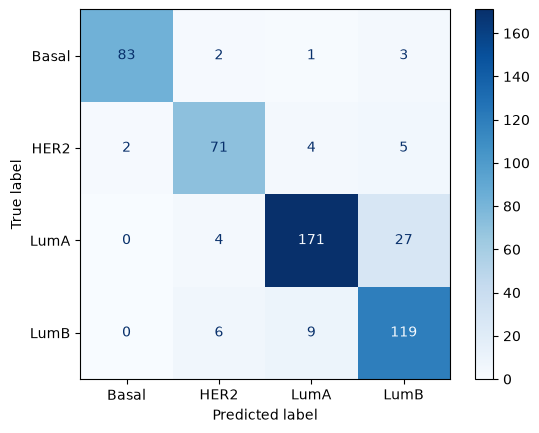

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Basal", "HER2", "LumA", "LumB"],
    cmap="Blues"
)

# MODEL 2: Logistic Regression + PCA

In [48]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.90)

X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)

print("Training:", X_train_pca.shape)
print("Validation:", X_val_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())

Training: (1182, 740)
Validation: (507, 740)
Explained variance: 0.9002296263725253


In [49]:
model_pca = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42)

model_pca.fit(X_train_pca, y_train)
y_val_pred_pca = model_pca.predict(X_val_pca)

In [50]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_pca))
print(classification_report(y_val, y_val_pred_pca))

Accuracy: 0.873767258382643
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        89
           1       0.79      0.84      0.82        82
           2       0.92      0.87      0.89       202
           3       0.82      0.86      0.84       134

    accuracy                           0.87       507
   macro avg       0.87      0.88      0.87       507
weighted avg       0.88      0.87      0.87       507



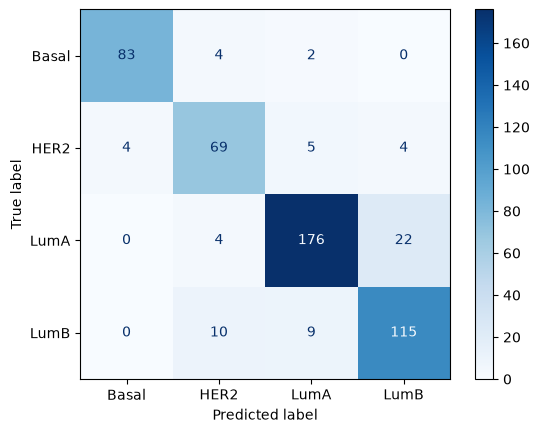

In [51]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_pca,
    display_labels=["Basal", "HER2", "LumA", "LumB"],
    cmap="Blues"
)

# Clustering

In [54]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []
for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    cluster_labels = kmeans.fit_predict(X_train)
    silhouette = silhouette_score(X_train, cluster_labels)

    results.append({
        "k": k,
        "silhouette_score": silhouette,
        "inertia": kmeans.inertia_
    })

results_df = pd.DataFrame(results)
print(results_df)

   k  silhouette_score       inertia
0  2          0.073996  1.754938e+07
1  3          0.075312  1.682076e+07
2  4          0.029104  1.644390e+07
3  5          0.028399  1.618991e+07
4  6          0.017457  1.595241e+07


In [55]:
import umap.umap_ as umap
import matplotlib.pyplot as plt

# Create UMAP representation
reducer = umap.UMAP(
    n_components=2,
    random_state=42)

X_train_umap = reducer.fit_transform(X_train)

print(X_train_umap.shape)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(1182, 2)


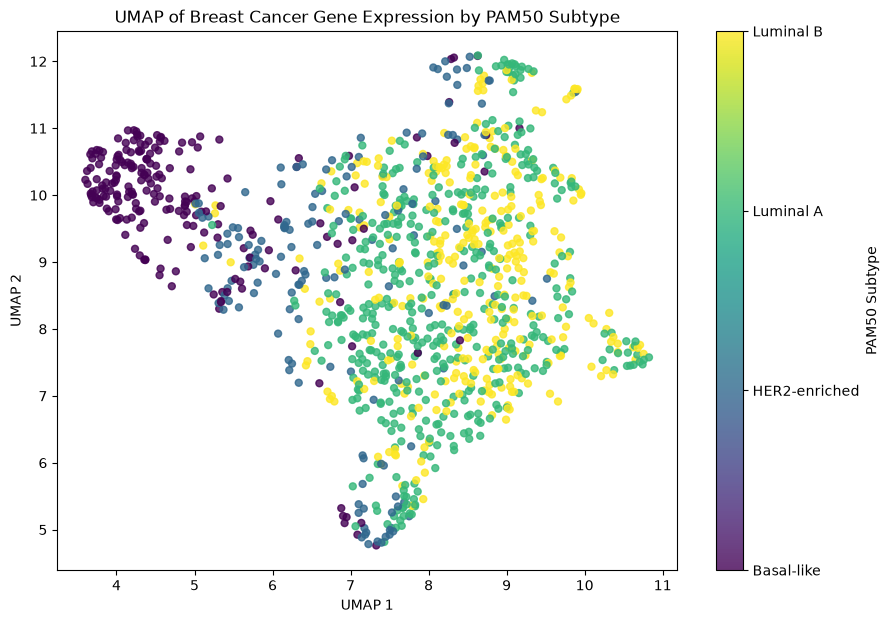

In [56]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_umap[:, 0],
    X_train_umap[:, 1],
    c=y_train,
    cmap="viridis",
    s=25,
    alpha=0.8
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP of Breast Cancer Gene Expression by PAM50 Subtype")

cbar = plt.colorbar(scatter, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(["Basal-like", "HER2-enriched", "Luminal A", "Luminal B"])
cbar.set_label("PAM50 Subtype")

plt.show()

In [57]:
reducer_supervised = umap.UMAP(
    n_components=2,
    random_state=42
)

X_train_umap_supervised = reducer_supervised.fit_transform(
    X_train,
    y=y_train
)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


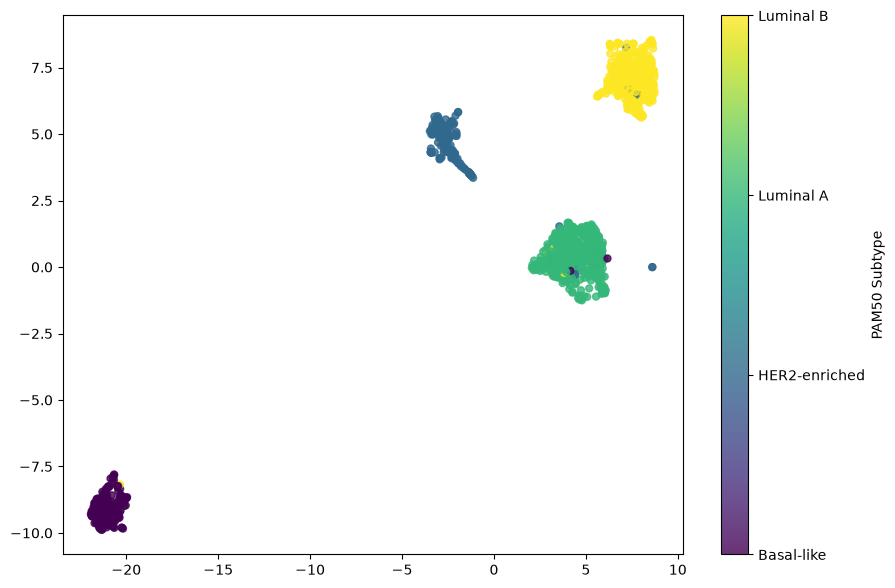

In [58]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_train_umap_supervised[:, 0],
    X_train_umap_supervised[:, 1],
    c=y_train,
    cmap="viridis",
    s=25,
    alpha=0.8
)

cbar = plt.colorbar(scatter, ticks=[0, 1, 2, 3])
cbar.ax.set_yticklabels(["Basal-like", "HER2-enriched", "Luminal A", "Luminal B"])
cbar.set_label("PAM50 Subtype")
plt.show()

In [59]:
from sklearn.metrics import silhouette_score

silhouette_unsupervised = silhouette_score(
    X_train_umap,
    y_train
)

silhouette_supervised = silhouette_score(
    X_train_umap_supervised,
    y_train
)

print("Unsupervised UMAP:", silhouette_unsupervised)
print("Supervised UMAP:", silhouette_supervised)

Unsupervised UMAP: 0.06243511661887169
Supervised UMAP: 0.7860207557678223


# Model 3: Logistic Regression + Removed pam50 genes

In [60]:
pam50_genes = [
    "ACTR3B", "ANLN", "BAG1", "BCL2", "BIRC5",
    "BLVRA", "CCNB1", "CCNE1", "CDC20", "CDC6",
    "NUF2", "CDH3", "CENPF", "CEP55", "CXXC5",
    "EGFR", "ERBB2", "ESR1", "EXO1", "FGFR4",
    "FOXA1", "FOXC1", "GPR160", "GRB7", "KIF2C",
    "NDC80", "KRT14", "KRT17", "KRT5", "MAPT",
    "MDM2", "MELK", "MIA", "MKI67", "MLPH",
    "MMP11", "MYBL2", "MYC", "NAT1", "ORC6",
    "PGR", "PHGDH", "PTTG1", "RRM2", "SFRP1",
    "SLC39A6", "TMEM45B", "TYMS", "UBE2C", "UBE2T"
]

In [61]:
pam50_columns = [
    col for col in X_train.columns
    if col.removesuffix("_EXPR") in pam50_genes
]
print("PAM50 genes found:", len(pam50_columns))

PAM50 genes found: 45


In [62]:
X_train_no_pam50 = X_train.drop(columns=pam50_columns)
X_val_no_pam50 = X_val.drop(columns=pam50_columns)

print("Original features:", X_train.shape[1])
print("Remaining features:", X_train_no_pam50.shape[1])

Original features: 15592
Remaining features: 15547


In [63]:
model_50 = LogisticRegression(
    random_state=42
)

model_50.fit(X_train_no_pam50, y_train)
y_val_pred_50 = model_50.predict(X_val_no_pam50)

In [64]:
print("Accuracy:", accuracy_score(y_val, y_val_pred_50))

print(classification_report(y_val, y_val_pred_50))

Accuracy: 0.873767258382643
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        89
           1       0.84      0.88      0.86        82
           2       0.92      0.85      0.88       202
           3       0.78      0.87      0.82       134

    accuracy                           0.87       507
   macro avg       0.88      0.88      0.88       507
weighted avg       0.88      0.87      0.88       507



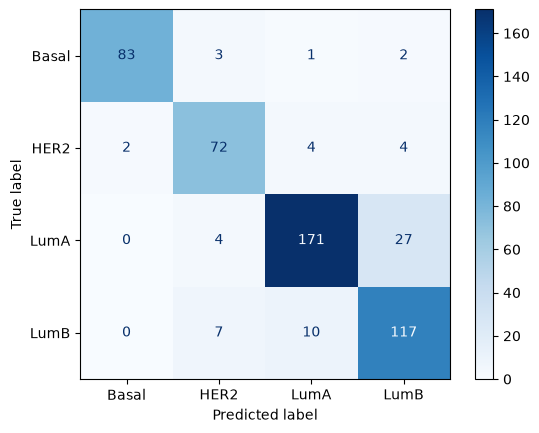

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_50,
    display_labels=["Basal", "HER2", "LumA", "LumB"],
    cmap="Blues"
)